# Mandatory assignment 3

**GitHub repository:** *https://github.com/leifeglie-wq/Tech2-Assignment3*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [14]:
import pandas as pd
df = pd.read_csv("SCF_10pct.csv")
print(df.count())                   #1

the_variables=["id", "year", "age", "educ", "stocks", "equity"];
df_copy=df.copy();

for variable in the_variables:
    counter=len(df_copy)
    df_copy=df_copy.dropna(subset=[variable])
    dropped=counter-len(df_copy)
    print(f"{variable}: {dropped} rows dropped, {len(df_copy)} rows remaining") #2


copy=len(df_copy)
df_filtered=df_copy[(df_copy["age"]>=25) & (df_copy["age"]<=89)]
print(
    f"end={len(df_filtered)} rows remaining after filtering for age between 25 and 89",
    f"dropped {copy - len(df_filtered)}") #3

df_filtered["direct"] = (df_filtered["stocks"] > 0).astype(int)
df_filtered["overall"] = (df_filtered["equity"] > 0).astype(int)    #4


id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64
id: 0 rows dropped, 5808 rows remaining
year: 0 rows dropped, 5808 rows remaining
age: 0 rows dropped, 5808 rows remaining
educ: 16 rows dropped, 5792 rows remaining
stocks: 18 rows dropped, 5774 rows remaining
equity: 16 rows dropped, 5758 rows remaining
end=5432 rows remaining after filtering for age between 25 and 89 dropped 326


***
## Part 2 — Participation rates

In [15]:
def participation_rate2(indicator):
    total = 0

    for value in indicator:
        total += value

    return total / len(indicator)*100


def participation_rate(indicator):
    return indicator.mean()*100

print(f"Overall participation rate: {participation_rate(df_filtered['overall']):.2f}%")
print(f"Direct participation rate: {participation_rate(df_filtered['direct']):.2f}%")

Overall participation rate: 49.41%
Direct participation rate: 16.96%


You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

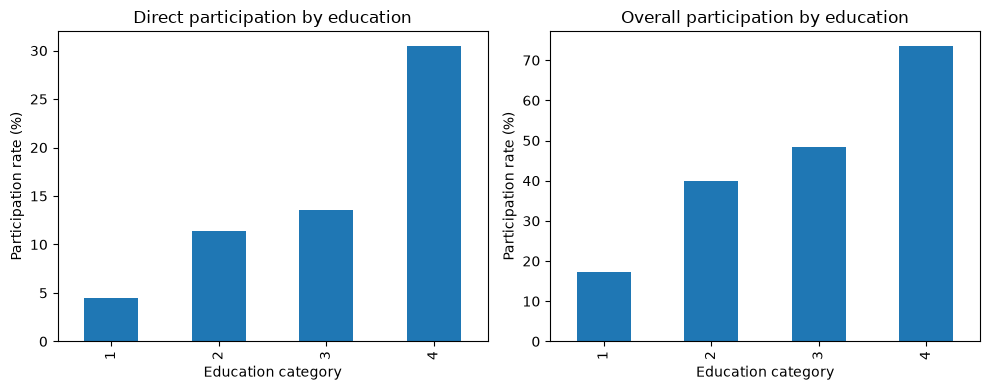

The figures show the more educated individuals have higher participation rates in both direct and overall stock market participation. This suggests that education level is positively correlated with stock market involvement.


In [16]:
import matplotlib.pyplot as plt

cat_vector = [1, 2, 3, 4]
direct_rates = []
overall_rates = []

for cats in cat_vector:
    group = df_filtered[df_filtered["educ"] == cats]

    direct_rate = participation_rate2(group["direct"])
    overall_rate = participation_rate2(group["overall"])

    direct_rates.append(direct_rate)
    overall_rates.append(overall_rate)

rates = pd.DataFrame(
    {"Direct": direct_rates, "Overall": overall_rates}, index=cat_vector
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

rates["Direct"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Direct participation by education")
axes[0].set_xlabel("Education category")
axes[0].set_ylabel("Participation rate (%)")

rates["Overall"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Overall participation by education")
axes[1].set_xlabel("Education category")
axes[1].set_ylabel("Participation rate (%)")

plt.tight_layout()
plt.show()

print("The figures show the more educated individuals have higher participation rates in both direct and overall stock market participation. This suggests that education level is positively correlated with stock market involvement.")

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

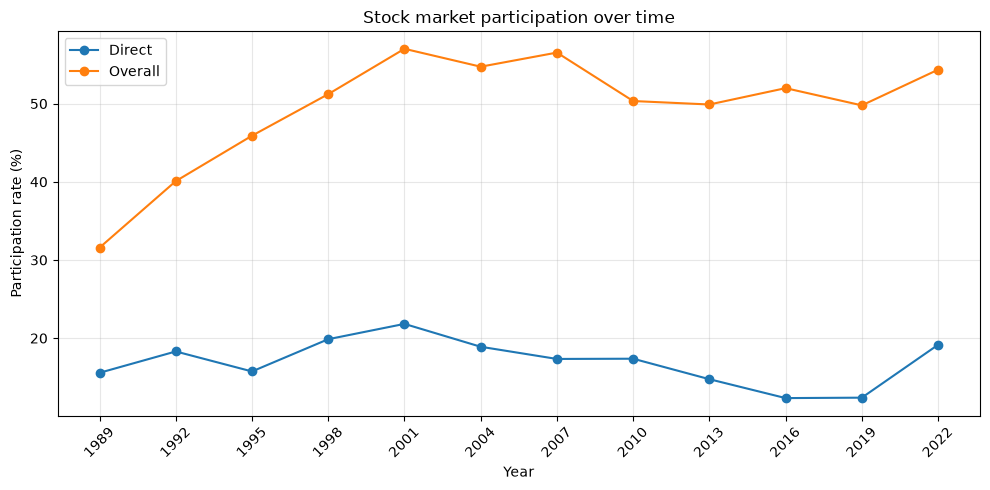

Direct change: 3.6 percentage points
Overall change: 22.8 percentage points
Both direct and overall stock market participation rose from 1989 to 2001, then it was overall declining until 2019 where it started to climb again


In [17]:
years = sorted(df_filtered["year"].unique())
direct_rates = []
overall_rates = []

for year in years:
    group = df_filtered[df_filtered["year"] == year]

    direct_rates.append(participation_rate2(group["direct"]))
    overall_rates.append(participation_rate2(group["overall"]))

plt.figure(figsize=(10, 5))
plt.plot(years, direct_rates, marker="o", label="Direct")
plt.plot(years, overall_rates, marker="o", label="Overall")
plt.title("Stock market participation over time")
plt.xlabel("Year")
plt.ylabel("Participation rate (%)")
plt.xticks(years, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

direct_change = direct_rates[-1] - direct_rates[0]
overall_change = overall_rates[-1] - overall_rates[0]

print(f"Direct change: {direct_change:.1f} percentage points")
print(f"Overall change: {overall_change:.1f} percentage points")

print("Both direct and overall stock market participation rose from 1989 to 2001, then it was overall declining until 2019 where it started to climb again")

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.
The instructions where everything was allowed, I downloaded the panda complete notes, started to code. I used the pandas documentation and AI as learning resources. I wrote the code for Parts 1 and 2, and used AI to clarify concepts and discuss possible approaches afterwards. I did not change any code with these clarifications or approaches. For Part 3, I calculated the participation rates by education category and used AI suggestions to create and refine the plots. Where my plots were initially ugly. For Part 4, AI helped me with some plotting commands and suggested using `sorted(df_filtered["year"].unique())` to obtain the years, rather than listing them manually. I wrote the years in a vector list but changed the command after review.It also suggested a way to organize the calculated rates in a DataFrame. I reviewed the suggestions and used those I understood and found useful. I chose to organize the calculations using lists and loops. In all loops and vector structures AI suggested other solutions than loops and vectors, but I kept my own solution in my coding design. Overall, AI helped me understand parts of the code and improve the plots’ visual presentation, it was a great learning assistant, while I made the final decisions about what to use.


